In [3]:
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
from adjustText import adjust_text
from shapely.geometry import LineString
import matplotlib.patheffects as pe
import os
from matplotlib.lines import Line2D
from matplotlib_scalebar.scalebar import ScaleBar

from utils.paths import VISUALIZATION_DIR, EXTERNAL_DIR

In [4]:
# Reading coordinates file

COOR_PATH = EXTERNAL_DIR / "stations_coordinates.csv"
coor_df = pd.read_csv(COOR_PATH)

# First five stations
coor_df.head()

,station_name,latitude,longitude
0,alipur,28.815339,77.153009
1,anand_vihar,28.647746,77.315450
2,ashok_vihar,28.696286,77.181552
3,bawana,28.776934,77.051134
4,chandni_chowk,28.659506,77.229525


In [5]:
removed_stations = ['aya_nagar', 'burari_crossing', 'crri_mathura_road', 'igi_airport_t3', 'lodhi_road', 'north_campus_du', 'alipur', 'anand_vihar', 'chandni_chowk', 'dilshad_garden', 'dtu', 'mandir_marg', 'nsit_dwarka', 'punjabi_bagh', 'shadipur', 'sirifort', 'r_k_puram']

rename = {
    "major_dhyan_chand_national_stadium": "MDCNS",
    "dr_karni_singh_shooting_range": "KSSR",
    "dwarka_sector_8": "Dwarka-8",
    "sri_aurobindo_marg": "Aurobindo Marg"
}

MAP_DIR = VISUALIZATION_DIR / "maps"
if not os.path.exists(MAP_DIR):
    os.mkdir(MAP_DIR)

selected_station_color = "#C2185B"  # deep magenta
unselected_station_color = "#DDDDDD"

In [6]:
# Convert to GeoDataFrame
stations = gpd.GeoDataFrame(coor_df, geometry=gpd.points_from_xy(coor_df["longitude"], coor_df["latitude"]), crs="EPSG:4326")

stations["station_name"] = stations["station_name"].replace(rename)

# Download Delhi's Boundary
place = "National Capital Territory of Delhi, India"
boundary = ox.geocode_to_gdf(place)

# Road network
graph = ox.graph_from_place(place, network_type="drive")
edges = ox.graph_to_gdfs(graph, nodes=False, edges=True)

# Convert everything to Web Mercator
boundary = boundary.to_crs(3857)
edges = edges.to_crs(3857)
stations = stations.to_crs(3857)

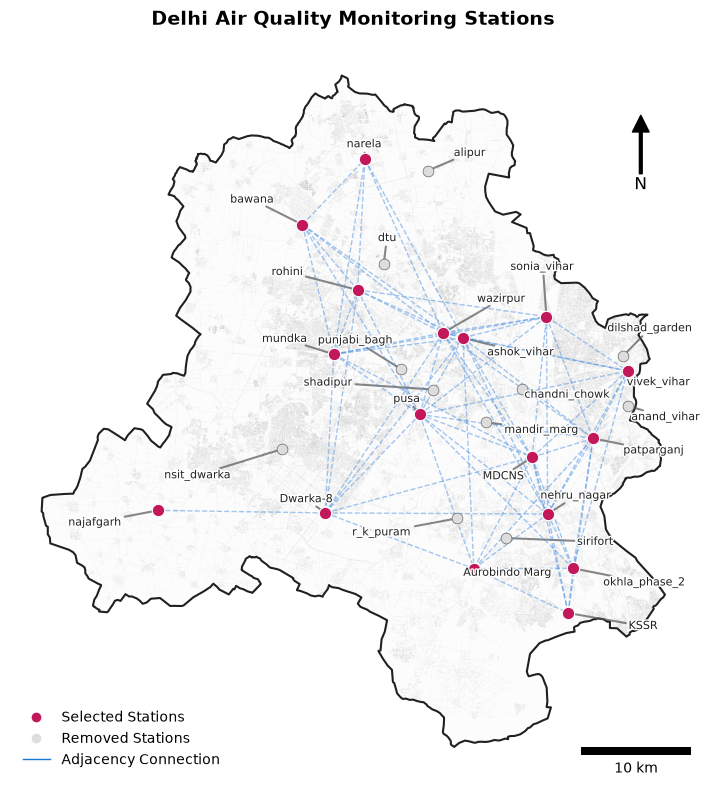

In [9]:
# Plot
fig, ax = plt.subplots(figsize=(8,8))

# Delhi polygon
boundary.plot(
    ax=ax,
    color="#FCFCFC",
    edgecolor="#202020",
    linewidth=1.5,
    zorder=0
)

# Roads
edges.plot(
    ax=ax,
    linewidth=0.15,
    alpha=0.08,
    color="#9e9e9e",
    zorder=1
)

selected = stations[~stations["station_name"].isin(removed_stations)]
selected = selected.reset_index(drop=True)

unselected = stations[stations["station_name"].isin(removed_stations)]
unselected = unselected.reset_index(drop=True)

ADJ_PATH = EXTERNAL_DIR / "Adjacency_distance_matrix.csv"
adj = pd.read_csv(ADJ_PATH)
adj = adj.set_index(adj.columns[0])

lines = []
for i in range(len(selected)):
    for j in range(i+1, len(selected)): # avoid duplicate
        if adj.values[i, j] == 1:
            p1 = selected.geometry.iloc[i]
            p2 = selected.geometry.iloc[j]
            lines.append(
                LineString([p1, p2])
            )

connections = gpd.GeoDataFrame(
    geometry=lines,
    crs=stations.crs
)

# Neighbor connections
connections.plot(
    ax=ax,
    color="#4A90E2",
    linewidth=1,
    alpha=0.5,
    linestyle="--",
    zorder=2
)

# Stations
unselected.plot(
    ax=ax,
    color=unselected_station_color,
    edgecolor="#666666",
    linewidth=0.5,
    markersize=60,
    zorder=3
)

selected.plot(
    ax=ax,
    color=selected_station_color,
    edgecolor="white",
    linewidth=0.8,
    markersize=80,
    zorder=4
)

# Station labels
texts = []
for x, y, label in zip(stations.geometry.x, stations.geometry.y, stations["station_name"]):
    txt = ax.text(x, y, label, fontsize=8, color="#222222", zorder=5)
    txt.set_path_effects([pe.withStroke(linewidth=2, foreground="white")])
    texts.append(txt)

adjust_text(
    texts,
    ax=ax,
    expand=(1.5, 1.8),
    force_text=(1.5, 2.0),
    force_static=(1.0, 1.2),
    force_pull=(0.02, 0.05),
    force_explode=(1.5, 2.0),
    max_move=40,
    iter_lim=1000,
    prevent_crossings=True,
    ensure_inside_axes=True,
    arrowprops=dict(
        arrowstyle="-",
        color="#555555",
        lw=1.5,
        alpha=0.7
    )
)

ax.add_artist(ScaleBar(1, location='lower right'))

# North arrow
ax.annotate('N', xy=(0.92, 0.90), xytext=(0.92, 0.80), arrowprops=dict(facecolor='black', width=2),ha='center', fontsize=12, xycoords='axes fraction', zorder=6)

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=selected_station_color, markersize=8,label='Selected Stations'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=unselected_station_color, markersize=8,label='Removed Stations'),
    Line2D([0], [0], color='#1976D2', lw=1, label='Adjacency Connection')
]
ax.legend(handles=legend_elements, loc='lower left', frameon=False)

# Title
plt.title("Delhi Air Quality Monitoring Stations", fontsize=14, fontweight="bold", pad=12)

ax.set_axis_off()
plt.tight_layout()

plt.savefig(os.path.join(MAP_DIR, "Delhi_AQI_Map.png"),
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
            )

plt.show()
plt.close()